# Lab 2 · Factorized FNO (FFNO) for infrasound boundary-layer propagation

<img src="../../assets/logos/amiad.png" width="120"/> <img src="../../assets/logos/cea.png" width="120"/> <img src="../../assets/logos/lmps.png" width="120"/> <img src="../../assets/logos/borelli.png" width="120"/>

**Authors:** E. Noëlé, Gatti, Lehmann, Millet, Clouteau<br>
**Affiliations:** AMIAD, CEA, LMPS, Borelli<br>
**Contact:** elodie.noele@TODO.example

**LETMA 2026 Summer School · Lab 2 of 3** — Lab 1: FNO for Burgers · Lab 3: Graph Neural Networks.

**One scientific question.** *A few ground receivers record infrasound from an explosion in the
atmospheric boundary layer. The recorded waveforms were shaped by the effective sound-speed
profile c_eff(z) — can a network learn to predict the waveforms directly from the profile, and
can we keep such an operator affordable?*

Pipeline of the lab: physics and hypotheses (section 1) -> the learning problem (section 2)
-> the factorized operator and its training (section 3) -> the loss and the optimizer race
(section 4) -> evaluation on unseen atmospheres (section 5).

**How to use this notebook.** Run the cells in order. The core path states every assumption as
a numbered hypothesis (H1, H2, …) — including the assumptions of the *physical solver* that
generates the data. Parts marked *optional* — the ray picture and hodograph of §1.1 and the
overfitting experiment of §4.3 — go deeper and can be skipped without breaking anything that
follows. The exercise cannot block you: an automatic checker compares your code with a
reference, and on failure the reference takes over. Runs on the Hedy cluster, Binder, Google Colab or any laptop CPU; no GPU and no pre-trained
model needed. Animations are inline widgets: press the play button inside each (on Hedy they
are shown as static filmstrips).

## §0 · Setup\n\nRun the two cells; check the device line.

In [1]:
# Portable setup: runs unchanged on the Hedy cluster, a laptop, Binder or Google Colab. Run this cell first.
import os, sys
from pathlib import Path
if 'google.colab' in sys.modules:                      # Google Colab: fetch the repository once
    import importlib.util, subprocess
    COLAB_ROOT = Path('/content/Tutorial_FNO_GNN_LETMA_AutumnSchool_2026')
    if not (COLAB_ROOT / 'fno_tuto').is_dir():
        subprocess.run(['git', 'clone', '-q', '--depth', '1',
                        'https://github.com/noeleel/Tutorial_FNO_GNN_LETMA_AutumnSchool_2026.git',
                        str(COLAB_ROOT)], check=True)
    os.environ['HEDY_PROJECT_ROOT'] = str(COLAB_ROOT)
project_root = next((p for p in [Path(os.environ.get('HEDY_PROJECT_ROOT', Path.cwd())),
                                  Path.cwd(), *Path.cwd().parents]
                     if (p / 'fno_tuto').is_dir() and (p / 'gnn_tuto').is_dir()), None)
if project_root is None:
    raise RuntimeError('Open this notebook inside the tutorial project directory.')
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

# LAB_PLOT_MODE=tk only for interactive SSH/X11 on Hedy (set before launching the kernel).
# Guard: the tk backend needs a WORKING X display - X11 forwarding usually does not survive
# the hop to a compute node, so we test it for real and fall back to inline plots.
from IPython import get_ipython
PLOT_MODE = os.environ.get('LAB_PLOT_MODE', 'inline').strip().lower()
if PLOT_MODE == 'tk':
    try:
        import tkinter
        tkinter.Tk().destroy()             # a real X round-trip, not just $DISPLAY
    except Exception:
        print('no usable X display -> falling back to inline plots (ssh -Y for tk windows)')
        PLOT_MODE = 'inline'
get_ipython().run_line_magic('matplotlib', PLOT_MODE)

import math, time
import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML, display

from fno_tuto.plotting import setup_style
setup_style()
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11, 'axes.titlesize': 12,
                     'axes.labelsize': 11, 'legend.fontsize': 10})
DEVICE = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
SEED = 0
torch.manual_seed(SEED); np.random.seed(SEED)

# Optional Hedy session profiling: active only on the cluster, silently skipped elsewhere.
HEDY_SESSION = None
try:
    from hedy_euporie.profiler import begin_session
    HEDY_SESSION = begin_session('lab_ffno_infrasound_solution', backend='torch')
except Exception:
    print('Hedy session profiling not available here (local/laptop run): continuing without it.')

def show_anim(fig, func, frames, interval=200, blit=False):
    """Inline JS animation in Jupyter/JupyterLab. On Hedy (Euporie cannot play the
    JavaScript animation) a static filmstrip of a few key frames is shown instead."""
    n_frames = frames if isinstance(frames, int) else len(frames)
    if HEDY_SESSION is not None:              # on Hedy: static filmstrip, no JS player
        picks = np.unique(np.linspace(0, max(n_frames - 1, 0), 6).round().astype(int))
        snaps = []
        for f in picks:
            func(int(f))
            fig.canvas.draw()
            snaps.append(np.asarray(fig.canvas.buffer_rgba())[:, :, :3])
        plt.close(fig)
        fig2, ax2 = plt.subplots(1, len(picks), figsize=(2.4 * len(picks), 2.9))
        for a, s, f in zip(np.atleast_1d(ax2), snaps, picks):
            a.imshow(s); a.set_xticks([]); a.set_yticks([])
            a.set_title(f'frame {int(f) + 1}/{n_frames}', fontsize=8)
        fig2.tight_layout(); plt.show()
    else:
        ani = animation.FuncAnimation(fig, func, frames=frames, interval=interval, blit=blit)
        plt.close(fig)          # suppress the empty static frame
        display(HTML(ani.to_jshtml()))

print(f'Python {sys.version.split()[0]} | torch {torch.__version__} | device {DEVICE}')


Profiling warning: CUDA counters unavailable: Invalid device argument 
Interactive session: lab_ffno_infrasound_solution | profiling on
Python 3.12.4 | torch 2.15.0+cu132 | device cuda


In [2]:
import torch.nn as nn
from fno_tuto.infrasound import Configuration, make_dataset, sample_ceff, ricker_source
from fno_tuto.models.ffno import FFNO2d, FactorizedSpectralConv2d
from fno_tuto.models.fno2d import SpectralConv2d       # for the parameter comparison
from fno_tuto.losses import get_loss
print('imports OK')

imports OK


## §1 · The physics, with every hypothesis

Low-frequency sound (a few hertz - infrasound at local ranges) propagates kilometres through
the atmospheric boundary layer. What a ground receiver records is governed by the **effective
sound speed**

$$c_{\mathrm{eff}}(z) = c(z) + u_{\parallel}(z),$$

the static sound speed plus the wind component *along the propagation plane*. In the boundary
layer (the lowest 2 km here) $c_{\mathrm{eff}}$ varies with altitude, and that vertical
structure is exactly what imprints itself on the ground recordings: profile in, waveforms out.

**The forward model we use (a transparent teaching solver).** For each frequency $\omega$, the
narrow-angle **parabolic equation** (PE) marches the complex field $u(r,z,\omega)$ in range:

$$2 i k_0\, \partial_r u = \partial_{zz}u + \big(k(z)^2 - k_0^2\big)u,
\qquad k(z) = \omega / c_{\mathrm{eff}}(z),\quad k_0 = \omega/c_{\mathrm{ref}},$$

by alternating a half diffraction step (FFT in $z$), a full refraction phase (pointwise in $z$),
and a half diffraction step (Strang splitting). The time trace at a receiver is the inverse FFT over
$\omega$ of $u$ at that range, weighted by the source spectrum.

**Every hypothesis, explicitly — physics (H1–H8) first:**

- **H1 (geometry).** 2-D vertical section $(r,z)$ with $z$ in [0, 2] km (the boundary layer)
  and $r$ in [0, 11] km; the profile is **range-independent**: $c_{\mathrm{eff}}$
  depends on $z$ only.
- **H2 (effective medium).** Wind enters only through $u_\parallel$; no cross-plane wind, no
  turbulence, no density stratification.
- **H3 (paraxiality).** One-way propagation, narrow angle (roughly $\lesssim 20^\circ$): no
  backscatter, no wide-angle caustics.
- **H4 (harmonic decomposition).** Frequencies propagate independently; band $[0.3, 4]$ Hz,
  the informative band of the source ($f_0 = 1.5$ Hz Ricker).
- **H5 (boundaries).** Reflecting ground (mirrored grid); the atmosphere above ~1.4 km is
  simply not modelled: a *nonphysical* sponge absorbs there everything that leaves the
  boundary layer upwards, so nothing reflects back artificially from the top of the domain.
- **H6 (source).** Point-like explosion at 20 m altitude; a single, simple Ricker wavelet,
  $f_0=1.5$ Hz.
- **H7 (receivers).** Four ground receivers at 2, 5, 8, 11 km; retarded time axis
  $\tau = t - r/c_{\mathrm{ref}}$.
- **H8 (amplitudes).** The 2-D scheme produces *relative* pressure; we learn relative waveforms,
  not absolute pascal.

… and, on the machine-learning side:

- **H9 (the operator).** $G^\dagger: c_{\mathrm{eff}}(\cdot) \mapsto \{p_j(\tau)\}_{j=1}^{4}$
  with the source and receivers **fixed** — and the four ground receivers are predicted
  **jointly, in one evaluation**: the output is a single (4 receivers x 256 samples) block.
- **H10 (data law).** Profiles are i.i.d. draws from a synthetic ensemble with **two opposite
  stratifications** (inversion-like: $c_\mathrm{eff}$ increasing with altitude, optionally a
  low-level jet; lapse-like: decreasing), plus the random Gaussian boundary-layer
  perturbations of H2; **not** observed atmospheres; splits (200 train / 28 validation /
  28 test) by sample index.
- **H11 (normalization).** Input standardized with training-set statistics; one global output
  scale (no per-trace normalization — the relative amplitudes carry physics).
- **H12 (metric).** Relative $L^2$ per atmosphere over all four traces.
- **H13 (architecture, §3).** The operator's spectral response is **separable** in the two Fourier
  axes of the output grid; and the waveforms are essentially band-limited in time (H4 again —
  you will check it yourself).

This lab has exactly the same skeleton as Lab 1: data pairs → network → loss → optimizer →
landscape. Only the objects change: the input is a *profile* $c_{\mathrm{eff}}(z)$ and the
output is a set of *signals* $p_j(\tau)$.

In [3]:
# ---- the parabolic march, written out in full: ONE frequency, snapshots of u(r,z) ----
CFG = Configuration()
z_m = np.linspace(0.0, CFG.z_max_m, CFG.n_alt)
dz = float(z_m[1] - z_m[0])

def march_snapshots(profile_mps, f_hz, every=3):
    """Narrow-angle PE at a single frequency; returns |u| sampled every `every` range steps."""
    c = np.asarray(profile_mps, float)
    z_ext = np.concatenate((z_m, -z_m[-2:0:-1]))          # mirrored ground (H5)
    c_ext = np.concatenate((c, c[-2:0:-1]))
    n_ext = z_ext.size
    kz = 2 * np.pi * np.fft.fftfreq(n_ext, d=dz)
    k0 = 2 * np.pi * f_hz / CFG.c_ref_mps
    k = 2 * np.pi * f_hz / c_ext                        # wavenumber at each altitude
    dif = np.exp(-0.25j * CFG.dr_m * kz**2 / k0)
    refr = np.exp(0.5j * CFG.dr_m * (k**2 - k0**2) / k0)
    sponge = np.exp(-0.6 * np.maximum(np.abs(z_ext)/1000.0 - 1.4, 0.0)**3)   # H5: nothing
    refr = refr * sponge                                   #      reflects back from above
    src = np.exp(-0.5 * ((np.abs(z_ext) - CFG.source_alt_m) / CFG.source_vertical_width_m)**2)
    u = (src / src.max()).astype(complex)                 # source at 20 m (H6)
    n_steps = int(round(11e3 / CFG.dr_m))                 # out to the last receiver (H7)
    snaps = []
    for step in range(1, n_steps + 1):
        u = np.fft.ifft(np.fft.fft(u) * dif)              # half diffraction
        u *= refr                                         # full refraction phase
        u = np.fft.ifft(np.fft.fft(u) * dif)              # half diffraction
        if step % every == 0:
            snaps.append(np.abs(u[:CFG.n_alt]).copy())    # physical z >= 0 half
    return np.asarray(snaps)
print('PE marcher defined: single frequency, returns |u(r,z)| snapshots every 4 x 50 m')

PE marcher defined: single frequency, returns |u(r,z)| snapshots every 4 x 50 m


demo atmosphere #1: c_eff goes from 323.8 m/s at the ground to 361.0 m/s at 2 km


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


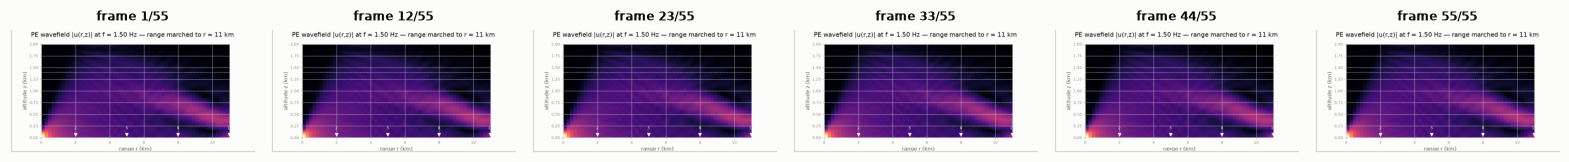

In [4]:
# ---- animation 1: one atmosphere, propagated: the input profile, seen as a wavefield ----
z_km = z_m / 1000.0
DATA = make_dataset(n=256, seed=123, config=CFG)  # generated once, reused in section 2
ceff_all = DATA['ceff_mps']
i_demo = next(i for i in range(len(ceff_all))     # the demo atmosphere: one whose rays
          if ceff_all[i, -1] > ceff_all[i, 0] + 5.0)   # return to the ground (several echoes)
print(f'demo atmosphere #{i_demo}: c_eff goes from {ceff_all[i_demo, 0]:.1f} m/s at the ground '
      f'to {ceff_all[i_demo, -1]:.1f} m/s at 2 km')

U_demo = march_snapshots(ceff_all[i_demo], f_hz=CFG.source_f0_hz, every=4)
n_frames, r_step = U_demo.shape[0], 4 * CFG.dr_m / 1000.0

fig, ax = plt.subplots(figsize=(7.2, 3.6))
im = ax.imshow(U_demo[0][:, None].T, extent=[0, r_step, 0, 2], aspect='auto', origin='lower',
               cmap='magma', vmin=0, vmax=U_demo.max())
ax.set_xlabel('range r (km)'); ax.set_ylabel('altitude z (km)')
ax.plot(CFG.station_ranges_km, [0.06] * 4, 'v', color='w', ms=7)
for r in CFG.station_ranges_km:
    ax.annotate(f'{int(r)}', (r, 0.18), fontsize=8, color='w', ha='center')
ax.axhline(1.4, color='w', ls='--', lw=0.7)          # sponge onset (H5)
title = fig.suptitle('')

def update(f):
    r_now = (f + 1) * r_step
    im.set_data(U_demo[:f + 1].T)
    im.set_extent([0, r_now, 0, 2])
    title.set_text(f'PE wavefield |u(r,z)| at f = {CFG.source_f0_hz:.2f} Hz — '
                   f'range marched to r = {r_now:.0f} km')
    return im, title

show_anim(fig, update, frames=n_frames, interval=180)

> **What to notice.** The PE wavefield is the bridge between input and output: it is the
> solution of the propagation problem that the network must learn to bypass. The triangles are
> the four ground receivers — the waveforms they record are the output of this lab. Everything
> lives in $z \in [0, 2]$ km: this is the boundary layer.

### 1.1 · Optional: the same physics as a ray picture, and as a hodograph

Two classical views make the problem tangible before any machine learning:

- **Ray tracing.** In a stratified medium the ray angle $e$ obeys
  $\frac{de}{ds} = -\frac{1}{c}\frac{dc}{dz}\cos e$: rays bend toward the slower medium, and
  the ground is a mirror (H5), so each ray that returns is a recorded arrival. The **input
  profile is shown next to the fan** (altitude on the $y$-axis, celerity on the $x$-axis, as in
  every profile plot of this lab).
- **Hodograph.** The recordings themselves, stacked by receiver range on an ABSOLUTE time axis:
  each trace is rescaled and placed at its range, so the arrival pattern *is* the travel-time
  curve. The ray-predicted first arrivals (shifted by the source wavelet of H6) land where the
  traces peak.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


10 ground arrivals within 11 km — each is one echo the receivers record


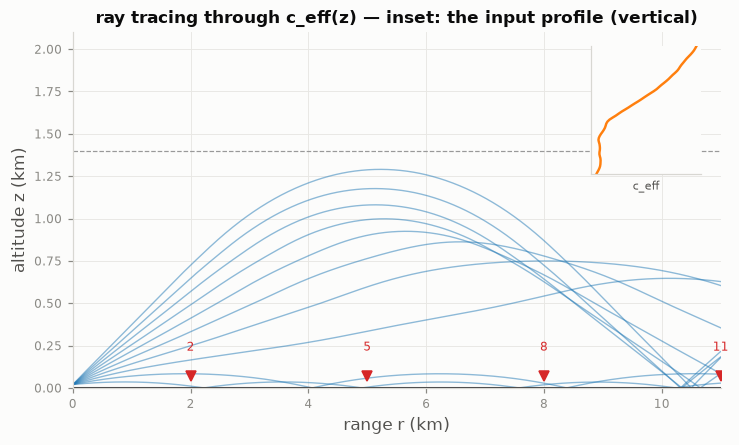

In [5]:
# ---- illustration by ray tracing: the demo atmosphere seen as rays ----
def trace_rays(c, angles_deg, r_max=11e3, ds=10.0, z_src=CFG.source_alt_m, z_top=2050.0):
    """Rays in a stratified medium: de/ds = (dc/dz)/c * cos(e); the ground is a mirror
    (H5): every ground hit is an arrival (range, reduced time)."""
    dcdz = np.gradient(c, z_m)
    rays, arrivals = [], []
    for e0 in angles_deg:
        e = np.radians(e0); x, z, t = 0.0, float(z_src), 0.0
        xs, zs = [x], [z]
        for _ in range(int(r_max / ds) + 800):
            cc = float(np.interp(z, z_m, c)); g = float(np.interp(z, z_m, dcdz))
            e -= (g / cc) * np.cos(e) * ds        # rays bend toward the slower medium
            x += np.cos(e) * ds; z += np.sin(e) * ds; t += ds / cc
            if z <= 0.0:                       # ground hit: reflect (Neumann boundary)
                z = -z; e = -e
                arrivals.append((x / 1000.0, t - x / CFG.c_ref_mps))
            if z >= z_top or x >= r_max:
                break
            xs.append(x); zs.append(z)
        rays.append((np.array(xs) / 1000.0, np.array(zs) / 1000.0))
    return rays, np.array(arrivals) if arrivals else np.zeros((0, 2))

angles = np.arange(2.0, 21.0, 2.0)
rays_demo, arr_demo = trace_rays(ceff_all[i_demo].astype(float), angles)
print(f'{len(arr_demo)} ground arrivals within 11 km — each is one echo the receivers record')

fig, ax = plt.subplots(figsize=(7.6, 4.2))
for xr, zr in rays_demo:
    ax.plot(xr, zr, lw=0.9, color='C0', alpha=0.5)
ax.plot([0, 11], [0, 0], color='0.25', lw=2)                        # reflecting ground
ax.plot(CFG.station_ranges_km, [0.07] * 4, 'v', color='C3', ms=7)
for r in CFG.station_ranges_km:
    ax.annotate(f'{int(r)}', (r, 0.22), fontsize=8, color='C3', ha='center')
ax.axhline(1.4, color='0.6', ls='--', lw=0.8)                        # sponge onset (H5)
inset = ax.inset_axes([0.80, 0.60, 0.17, 0.36])
inset.plot(ceff_all[i_demo], z_km, color='C1', lw=1.6)               # input profile (vertical)
inset.set_ylim(0, 2); inset.set_xticks([]); inset.set_yticks([])
inset.set_xlabel('c_eff', fontsize=7)
ax.set_xlim(0, 11); ax.set_ylim(0, 2.1)
ax.set_xlabel('range r (km)'); ax.set_ylabel('altitude z (km)')
ax.set_title('ray tracing through c_eff(z) — inset: the input profile (vertical)', fontsize=11)
plt.show()

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


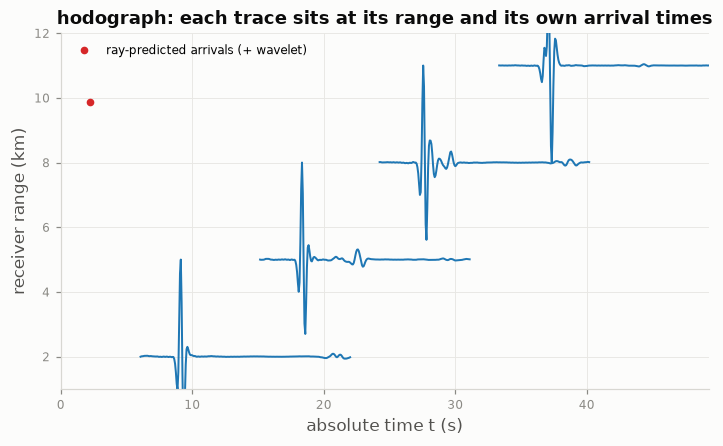

the traces arrive at t = r/c_ref plus the wavelet delay: the arrivals move to later
times with range (they are NOT stacked), and they land where the ray prediction puts
them. Rays are the high-frequency limit of the PE (H3): the match is qualitative.


In [6]:
# ---- the hodograph: the recordings, at their TRUE arrival times, with the rays ----
tau_np = DATA['tau_s']
t_abs = [tau_np + r * 1000.0 / CFG.c_ref_mps for r in CFG.station_ranges_km]  # t = tau + r/c_ref
fig, ax = plt.subplots(figsize=(7.6, 4.2))
for j, r in enumerate(CFG.station_ranges_km):
    tr = DATA['p'][i_demo, j] / (np.abs(DATA['p'][i_demo, j]).max() + 1e-9)
    ax.plot(t_abs[j], r + 3.0 * tr, color='C0', lw=1.3)     # each trace at its own times
if len(arr_demo):
    ok = arr_demo[:, 0] <= 11
    t_ray = CFG.source_center_tau_s + arr_demo[ok, 1] + arr_demo[ok, 0] * 1000.0 / CFG.c_ref_mps
    ax.plot(arr_demo[ok, 0], t_ray, 'o', ms=4, color='C3',
            label='ray-predicted arrivals (+ wavelet)')
    ax.legend(fontsize=8, loc='upper left')
ax.set_xlabel('absolute time t (s)'); ax.set_ylabel('receiver range (km)')
ax.set_ylim(1, 12); ax.set_xlim(0, t_abs[-1][-1])
ax.set_title('hodograph: each trace sits at its range and its own arrival times')
plt.show()
print('the traces arrive at t = r/c_ref plus the wavelet delay: the arrivals move to later')
print('times with range (they are NOT stacked), and they land where the ray prediction puts')
print('them. Rays are the high-frequency limit of the PE (H3): the match is qualitative.')

## §2 · The learning problem

We generate 256 synthetic atmospheres (H10), solve the PE for each (about 50 ms per atmosphere),
and learn **H9** directly: profile in, four waveforms out. The PE march is the expensive part
(hours in operational 3-D settings); the trained operator will take milliseconds.

profiles: (256, 64) | traces: (256, 4, 256) | receivers at [2.0, 5.0, 8.0, 11.0] km


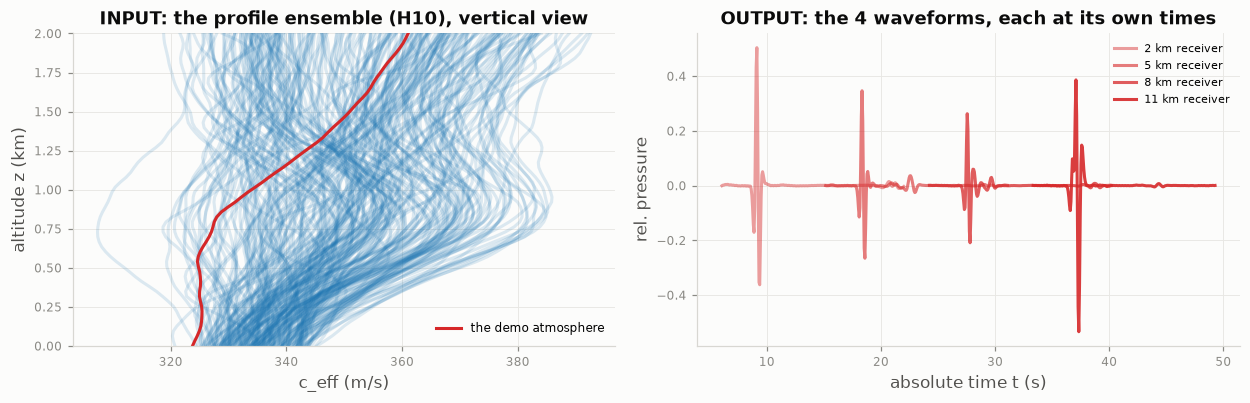

In [7]:
# ---- dataset (H10): the 256 atmospheres already generated in section 1 ----
ceff = torch.tensor(DATA['ceff_mps']).float()          # (64, 64)  profiles c_eff(z)
P = torch.tensor(DATA['p']).float()                    # (64, 4, 256) traces p_j(tau)
tau_s = torch.tensor(DATA['tau_s']).float()
ranges_km = DATA['ranges_km']
print('profiles:', tuple(ceff.shape), '| traces:', tuple(P.shape),
      '| receivers at', [float(r) for r in ranges_km], 'km')

fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.8))
for row in ceff.numpy():
    ax[0].plot(row, z_km, color='C0', alpha=0.15)
ax[0].plot(ceff[i_demo].numpy(), z_km, color='C3', lw=2, label='the demo atmosphere')
ax[0].set_ylim(0, 2)
ax[0].set_ylabel('altitude z (km)'); ax[0].set_xlabel('c_eff (m/s)')
ax[0].legend(fontsize=8, loc='lower right')
ax[0].set_title('INPUT: the profile ensemble (H10), vertical view')
for j, r in enumerate(CFG.station_ranges_km):
    ax[1].plot(tau_s + r * 1000.0 / CFG.c_ref_mps, P[i_demo, j] / P.abs().max(),
               color='C3', alpha=0.45 + 0.15 * j, label=f'{int(r)} km receiver')
ax[1].set_xlabel('absolute time t (s)'); ax[1].set_ylabel('rel. pressure')
ax[1].legend(fontsize=7); ax[1].set_title('OUTPUT: the 4 waveforms, each at its own times')
plt.tight_layout(); plt.show()

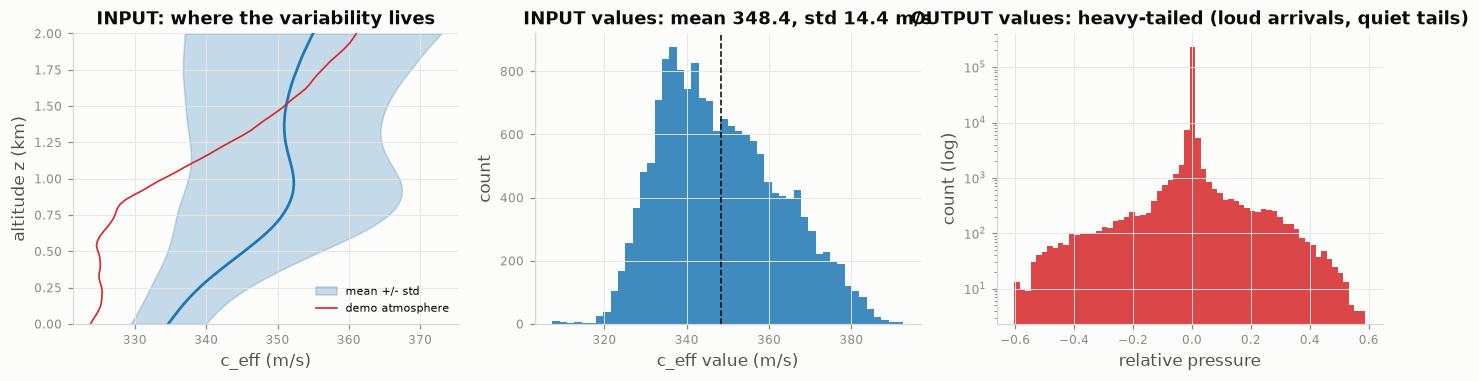

input c_eff: mean 348.4 +/- 14.4 m/s | output trace energies spread 0.4 to 2.0 (x4.8) - the imbalance of section 4, in numbers


In [8]:
# ---- the statistical distributions of the INPUTS and the OUTPUTS (know your data!) ----
fig, ax = plt.subplots(1, 3, figsize=(12.8, 3.6))
m_np = ceff.mean(0).numpy(); s_np = ceff.std(0).numpy()
ax[0].fill_betweenx(z_km, m_np - s_np, m_np + s_np, color='C0', alpha=0.25, label='mean +/- std')
ax[0].plot(m_np, z_km, color='C0', lw=1.8)
ax[0].plot(ceff[i_demo].numpy(), z_km, color='C3', lw=1.1, label='demo atmosphere')
ax[0].set_ylim(0, 2); ax[0].set_ylabel('altitude z (km)'); ax[0].set_xlabel('c_eff (m/s)')
ax[0].set_title('INPUT: where the variability lives')
ax[0].legend(fontsize=7, loc='lower right')
ax[1].hist(ceff.numpy().ravel(), bins=48, color='C0', alpha=0.85)
ax[1].axvline(float(ceff.mean()), color='k', ls='--', lw=1)
ax[1].set_xlabel('c_eff value (m/s)'); ax[1].set_ylabel('count')
ax[1].set_title(f'INPUT values: mean {float(ceff.mean()):.1f}, std {float(ceff.std()):.1f} m/s')
ax[2].hist(P.numpy().ravel(), bins=64, color='C3', alpha=0.85)
ax[2].set_yscale('log'); ax[2].set_xlabel('relative pressure'); ax[2].set_ylabel('count (log)')
ax[2].set_title('OUTPUT values: heavy-tailed (loud arrivals, quiet tails)')
plt.tight_layout(); plt.show()
e_amps = P.flatten(1).norm(dim=1)
print(f'input c_eff: mean {float(ceff.mean()):.1f} +/- {float(ceff.std()):.1f} m/s | '
      f'output trace energies spread {float(e_amps.min()):.1f} to {float(e_amps.max()):.1f} '
      f'(x{float(e_amps.max() / e_amps.min()):.1f}) - the imbalance of section 4, in numbers')

In [9]:
# ---- tensors and splits (H10, H11) ----
NTR, NVA, NTE = 200, 28, 28
c_mu, c_sd = ceff[:NTR].mean(), ceff[:NTR].std()       # input standardization, train stats only
p_sd = P[:NTR].std()                                   # ONE global output scale (H11)
Xc = ((ceff - c_mu) / c_sd).to(DEVICE)                 # (64, 64)
Yn = (P / p_sd).to(DEVICE)                             # (64, 4, 256) normalized

Xtr, Ytr = Xc[:NTR], Yn[:NTR]
Xva, Yva = Xc[NTR:NTR + NVA], Yn[NTR:NTR + NVA]
Xte, Yte = Xc[NTR + NVA:], Yn[NTR + NVA:]
print(f'train {NTR} | validation {NVA} | test {NTE} atmospheres '
      f'(test untouched until section 5)')

train 200 | validation 28 | test 28 atmospheres (test untouched until section 5)


## §3 · The FFNO: factorize the Fourier layers

Lab 1's FNO mixed channels with one complex matrix **per mode**. On a 2-D grid $(x, y)$ a full
spectral layer needs a matrix **per pair of modes**, $R[k_x, k_y]$: for $C$ channels, $m_x{\times}m_y$
pairs, that is $C^2\, m_x m_y$ complex parameters per layer. The **Factorized** FNO (Tran et al.,
ICLR 2023) replaces one 2-D spectral convolution by the **sum of two 1-D ones**:

$$(K v)^{\wedge}[k_x, k_y] = R_x[k_x]\, \hat v[k_x, k_y] + R_y[k_y]\, \hat v[k_x, k_y],$$

with $C^2 (m_x + m_y)$ parameters — a **tensor rank-1 (sum-separable) constraint** on the filter.
Two further ideas make deep stacks affordable: transformer-style residual blocks
$v \leftarrow v + \mathrm{FF}(\mathrm{GELU}(K(\mathrm{Norm}(v))))$ (the identity path keeps
many layers trainable), and optional weight sharing.

**Our operator (H9).** The *input* is a 1-D profile, the *output* is a 2-D grid (receiver × time):

1. **Encode altitude**: a small 1-D conv pool summarizes $c_{\mathrm{eff}}(z)$ into $k=16$ numbers
   per atmosphere.
2. **Decode on the (receiver, time) grid**: broadcast those $k$ channels onto the $4{\times}256$
   grid, add coordinate channels (the FFNO does this internally), and run $L=4$ factorized blocks:
   the spectral conv along **time** synthesizes waveform structure from the profile features
   (H13 + H4: infrasound is band-limited — Exercise F2 checks it), the one along **receivers**
   couples the four ranges (only 2 modes exist there: 4 points).
3. **Project** to 1 channel: the four normalized traces.

**Where is the computation?** In a learned latent space, as in Lab 1: the encoder summarizes the
profile into $k=16$ numbers; the factorized blocks mix those features across the (receiver,
time) grid; the projector reads them back to pressure. Nothing fixes what the 16 channels mean —
they are learned features; what the architecture fixes is only the input/output contract.

> **What factorization costs.** A separable filter cannot couple $k_x$ with $k_y$:
> phase terms of the form $e^{i(\alpha k_x + \beta k_y)}$ with *both* axes varying are
> unreachable in one layer. This is a hypothesis (H13), and in exchange you save a factor
> $\approx m_x m_y/(m_x+m_y)$ of spectral parameters — at $m_x=m_y=32$ that is 16×.

**Exercise F2.** Complete `signal_spectrum` (one line: two NumPy calls) and check H4/H13
yourself: where does the energy of a recorded trace live in frequency?
Not passing yet? The checker falls back to the NumPy reference — read the hint after class.

In [10]:
import numpy as np

def signal_spectrum(waveform, dt):
    """Real waveform (Nt,) -> (frequencies in Hz, complex one-sided spectrum)."""
    return np.fft.rfftfreq(len(waveform), d=dt), np.fft.rfft(waveform)

F2: your spectrum is correct


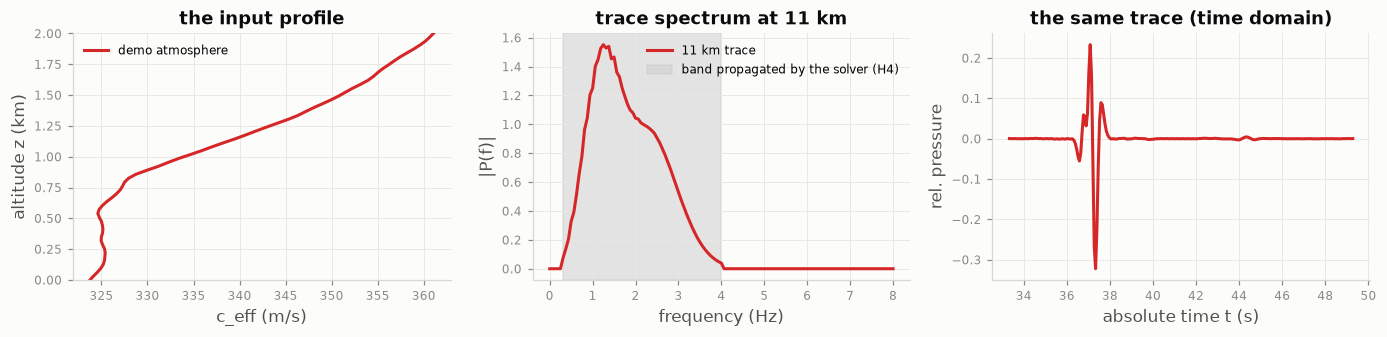

H13 in the time direction: keeping ~64 of 129 time modes covers the whole band — exactly the truncation the FFNO will make.


In [11]:
# ---- check F2 against the NumPy reference, then look at the physics it reveals ----
trace = P[i_demo, 3]
f_ref, spec_ref = np.fft.rfftfreq(len(trace), d=CFG.dt_s), np.fft.rfft(trace)
try:
    f_stu, spec_stu = signal_spectrum(trace, CFG.dt_s)
    ok = np.allclose(f_stu, f_ref) and np.allclose(spec_stu, spec_ref)
except Exception as exc:
    ok = False
    print('your function raised:', type(exc).__name__, exc)
print('F2:', 'your spectrum is correct' if ok else 'not correct yet - using the reference below')

fig, ax = plt.subplots(1, 3, figsize=(12.8, 3.2))
ax[0].plot(ceff[i_demo].numpy(), z_km, color='C3', label='demo atmosphere')
ax[0].set_ylim(0, 2); ax[0].set_ylabel('altitude z (km)'); ax[0].set_xlabel('c_eff (m/s)')
ax[0].legend(fontsize=8); ax[0].set_title('the input profile')
ax[1].plot(f_ref, np.abs(spec_ref), color='C3', label='11 km trace')
ax[1].axvspan(CFG.f_min_hz, CFG.f_max_hz, color='0.8', alpha=0.5,
              label='band propagated by the solver (H4)')
ax[1].set_xlabel('frequency (Hz)'); ax[1].set_ylabel('|P(f)|'); ax[1].legend(fontsize=8)
ax[1].set_title('trace spectrum at 11 km')
ax[2].plot(tau_s + 11 * 1000.0 / CFG.c_ref_mps, trace, color='C3')
ax[2].set_xlabel('absolute time t (s)'); ax[2].set_ylabel('rel. pressure')
ax[2].set_title('the same trace (time domain)')
plt.tight_layout(); plt.show()
print('H13 in the time direction: keeping ~64 of 129 time modes covers the whole band — '
      'exactly the truncation the FFNO will make.')

In [12]:
# ---- the operator of H9, assembled from the packaged FFNO2d ----
class InfrasoundFFNO(nn.Module):
    """c_eff(z) -> (4, 256) normalized traces: altitude encoder + FFNO over (receiver, time)."""
    def __init__(self, k=16, width=16, modes=(2, 64), n_layers=4):
        super().__init__()
        self.k = k
        self.encoder = nn.Sequential(                       # 1-D conv + pool along altitude
            nn.Conv1d(1, 32, 5, padding=2), nn.GELU(),
            nn.AdaptiveAvgPool1d(8), nn.Flatten(), nn.Linear(32 * 8, k), nn.GELU())
        self.ffno = FFNO2d(in_channels=k, out_channels=1, width=width, modes=modes,
                           n_layers=n_layers, grid=True, proj_hidden=64)

    def forward(self, c):                                  # c: (B, 64) standardized profile
        h = self.encoder(c.unsqueeze(1))                   # (B, k) summary of the atmosphere
        v = h.view(-1, self.k, 1, 1).expand(-1, self.k, 4, 256)   # broadcast onto the grid
        return self.ffno(v).squeeze(1)                     # (B, 4, 256) normalized traces

torch.manual_seed(0)
ffno = InfrasoundFFNO()
n_par = sum(p.numel() * (2 if p.is_complex() else 1) for p in ffno.parameters())
# The factorization, in parameters, at our sizes (C = width = 16, mx = 2, my = 64):
C, mx, my = 16, 2, 64
full = C * C * mx * my
fact = C * C * (mx + my)
print(f'FFNO operator: {n_par:,} real parameters')
print(f'spectral parameters per layer at (mx, my)=({mx},{my}): full FNO {full:,} vs '
      f'factorized {fact:,} complex weights -> {full/fact:.0f}x fewer')

FFNO operator: 145,345 real parameters
spectral parameters per layer at (mx, my)=(2,64): full FNO 32,768 vs factorized 16,896 complex weights -> 2x fewer


final validation rel-L2 (normalized traces): 0.2116 (recall: 1.0 = predicting zero)


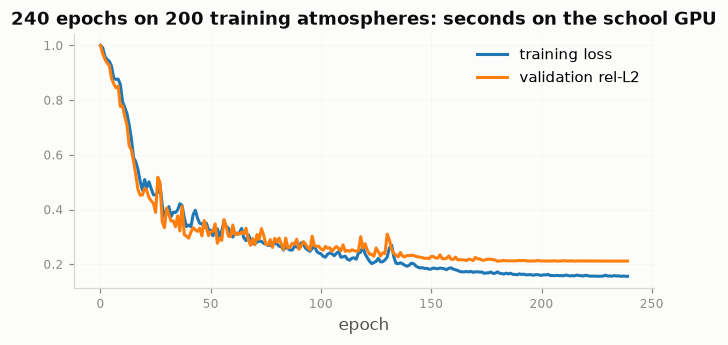

In [13]:
# ---- training loop (same skeleton as Lab 1: AdamW + cosine, instrumented) ----
def fit_ffno(model, *, epochs=240, batch=16, lr=2e-3, wd=1e-5, loss_name='rel_l2',
             snap_every=12, n_snap=3, seed=0):
    torch.manual_seed(seed)
    loss_fn = get_loss(loss_name)
    decay, no_decay = [], []
    for p in model.parameters():
        (no_decay if (p.is_complex() or p.ndim <= 1) else decay).append(p)
    opt = torch.optim.AdamW([{'params': decay, 'weight_decay': wd},
                             {'params': no_decay, 'weight_decay': 0.0}], lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs * math.ceil(NTR / batch))
    model = model.to(DEVICE)
    hist = {'train': [], 'val': []}
    snaps = []
    gen = torch.Generator().manual_seed(seed)
    for ep in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(NTR, generator=gen)
        tot, nb = 0.0, 0
        for i in range(0, NTR, batch):
            idx = perm[i:i + batch]
            opt.zero_grad(set_to_none=True)
            loss = loss_fn(model(Xtr[idx]), Ytr[idx])
            loss.backward(); opt.step(); sched.step()
            tot += loss.item(); nb += 1
        model.eval()
        with torch.no_grad():
            val = get_loss('rel_l2')(model(Xva), Yva).item()
        hist['train'].append(tot / nb); hist['val'].append(val)
        if snap_every and (ep % snap_every == 0 or ep == 1):
            with torch.no_grad():
                snaps.append((ep, model(Xva[:n_snap]).cpu().numpy()))
    return hist, snaps

theta_init_ffno = None
torch.manual_seed(0)
ffno = InfrasoundFFNO()
hist, snaps = fit_ffno(ffno)          # 240 epochs (the default)
print(f"final validation rel-L2 (normalized traces): {hist['val'][-1]:.4f} "
      f"(recall: 1.0 = predicting zero)")
fig, ax = plt.subplots(figsize=(6.8, 3))
ax.plot(hist['train'], label='training loss')
ax.plot(hist['val'], label='validation rel-L2')
ax.set_xlabel('epoch'); ax.legend(); ax.grid(alpha=0.3)
ax.set_title('240 epochs on 200 training atmospheres: seconds on the school GPU')
                
plt.show()

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


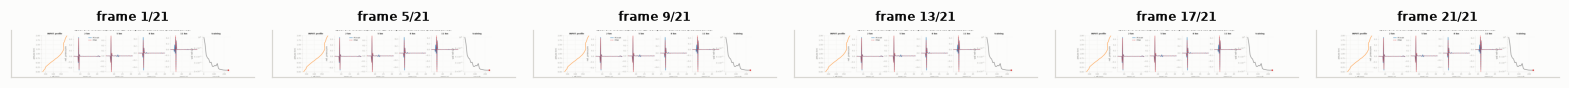

In [14]:
# ---- animation 2: waveforms emerging from a profile, epoch by epoch ----
ep0, pr0 = snaps[0]
fig, ax = plt.subplots(1, 6, figsize=(15.5, 3.0))
truth = P[NTR:NTR + 3].numpy()
ax[0].plot(Xva[0].cpu().numpy() * float(c_sd) + float(c_mu), z_km, color='C1', lw=1.8)
ax[0].set_ylim(0, 2); ax[0].set_xlabel('c_eff (m/s)', fontsize=8)
ax[0].set_ylabel('altitude (km)', fontsize=8)
ax[0].set_title('INPUT profile', fontsize=9)
lines = []
for j in range(4):
    t_j = tau_s + ranges_km[j] * 1000.0 / CFG.c_ref_mps     # absolute time per receiver
    ax[1 + j].plot(t_j, truth[0, j], color='C0', lw=1.8, label='PE truth')
    (ln,) = ax[1 + j].plot(t_j, pr0[0, j] * float(p_sd), color='C3', ls='--', lw=1.5, label='FFNO')
    ax[1 + j].set_title(f'{int(ranges_km[j])} km', fontsize=9)
    ax[1 + j].set_xlim(float(t_j[0]), float(t_j[-1]))
    ax[1 + j].set_xlabel('time t (s)', fontsize=8); ax[1 + j].grid(alpha=0.3)
    lines.append(ln)
ax[1].set_ylabel('rel. pressure'); ax[1].legend(fontsize=7)
(loss_ln,) = ax[5].plot([s[0] for s in snaps], [hist['val'][s[0] - 1] for s in snaps], color='0.4')
(dot,) = ax[5].plot([], [], 'o', color='C3')
ax[5].set_xlabel('epoch'); ax[5].set_ylabel('val rel-L2'); ax[5].grid(alpha=0.3)
ax[5].set_yscale('log'); ax[5].set_title('training', fontsize=9)
title = fig.suptitle('', y=1.04)

def update(f):
    ep, pr = snaps[f]
    for j in range(4):
        lines[j].set_ydata(pr[0, j] * float(p_sd))
    dot.set_data([ep], [hist['val'][ep - 1]])
    title.set_text(f'epoch {ep}: one atmosphere in, ALL FOUR ground receivers out (predicted jointly)')

show_anim(fig, update, frames=len(snaps), interval=450)

> **What to notice.** The network first learns the **arrival time** (phase), then the envelope,
> then the interference detail. Phase is the hard part: a travel-time error of a few percent is an
> $O(1)$ waveform error even if every amplitude is right. This is why waveform losses are
> delicate — and it motivates §4.

## §4 · The loss, its landscape, and the optimizer race

The **hyperparameters of the loss** here, in the sense of *choices made about the objective*:

1. **Loss family.** Relative $L^2$ (per atmosphere, all four traces) vs MSE. Relative errors put
   *every atmosphere* on the same footing; MSE chases the loud atmospheres. Since the four traces
   of one atmosphere share a normalization (H11), both are reasonable — but they define different
   goals, and on real (heterogeneous-amplitude) data the choice is an experiment, not a detail.
2. **Weight decay $\lambda$** in the AdamW objective $\mathcal L + \lambda\|\theta\|^2_2$
   (applied to real weights only, never to the complex spectral weights).
3. **Learning rate $\eta$**: chooses the trajectory through the landscape (Lab 1, §4; we reuse the
   two-direction slice and the animated optimizer race, in compact form).

rel-L2, lambda=1e-5     : final val rel-L2 = 0.2756


MSE,    lambda=1e-5     : final val rel-L2 = 0.3007


rel-L2, lambda=1 (aggressive): final val rel-L2 = 0.2880
sweep: 17 s on cuda


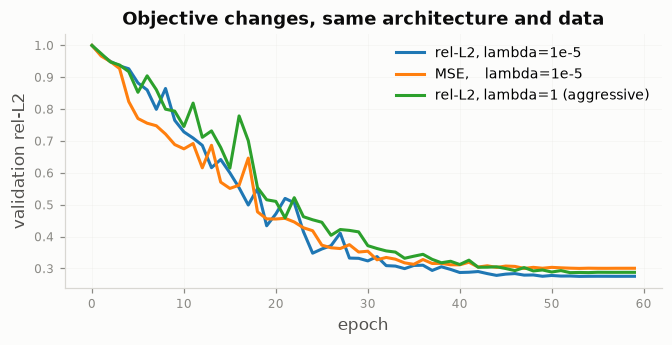

In [15]:
# ---- 4.1: loss family + weight decay, on this task ----
t0 = time.time()
configs = {'rel-L2, lambda=1e-5': dict(loss_name='rel_l2', wd=1e-5),
           'MSE,    lambda=1e-5': dict(loss_name='l2',     wd=1e-5),
           'rel-L2, lambda=1 (aggressive)': dict(loss_name='rel_l2', wd=1.0)}
sweep2 = {}
for name, kw in configs.items():
    torch.manual_seed(0)
    h, _ = fit_ffno(InfrasoundFFNO(), epochs=60, **kw)
    sweep2[name] = h
    print(f'{name:24s}: final val rel-L2 = {h["val"][-1]:.4f}')
print(f'sweep: {time.time()-t0:.0f} s on {DEVICE}')

fig, ax = plt.subplots(figsize=(7, 3))
for name, h in sweep2.items():
    ax.plot(h['val'], label=name)
ax.set_xlabel('epoch'); ax.set_ylabel('validation rel-L2'); ax.legend(fontsize=9); ax.grid(alpha=0.3)
ax.set_title('Objective changes, same architecture and data')
plt.show()

**Reading the sweep.** (i) The relative $L^2$ reaches a better validation error than MSE on this
task — it refuses to sacrifice the quiet atmospheres. (ii) Weight decay only becomes visible when
pushed to aggressive values ($\lambda=1$ with AdamW — decoupled decay shrinks weights by
$\eta\lambda$ per step, so at this small scale mild $\lambda$ does almost nothing); with this
boundary-layer-perturbed ensemble the aggressive $\lambda$ slightly *hurts*: the fine
profile-to-waveform detail the operator must fit is exactly what a strong shrinkage prior
suppresses. **Never report a hyperparameter sweep without its scale:**
$\lambda=10^{-4}$ on one problem and $\lambda=1$ on another can be the same setting, and the
sign of the effect is data-dependent.**

In [16]:
# ---- 4.2: the loss landscape on a 2-D slice, and the optimizer trajectories ----
def flat(m):
    parts = []
    for q in m.parameters():
        v = q.detach().reshape(-1)
        parts.append(torch.view_as_real(v).flatten() if v.is_complex() else v.flatten())
    return torch.cat([t.cpu() for t in parts])

def load_flat(m, vec):
    i = 0
    for q in m.parameters():
        n = q.numel()
        if q.is_complex():
            q.data.copy_(torch.view_as_complex(vec[i:i + 2 * n].reshape(*q.shape, 2).to(q.device)))
            i += 2 * n
        else:
            q.data.copy_(vec[i:i + n].view_as(q).to(q.device)); i += n

torch.manual_seed(0)
theta_star = flat(ffno)                       # trained operator
theta_init = flat(InfrasoundFFNO())           # same seed -> the exact starting point
d1 = theta_init - theta_star; s0 = d1.norm(); d1 = d1 / s0
g = torch.Generator().manual_seed(1)
d2 = torch.randn_like(d1); d2 = d2 / d2.norm()

xb, yb = Xtr[:16], Ytr[:16]                   # fixed batch: deterministic landscape
probe = InfrasoundFFNO().to(DEVICE)
loss_fn = get_loss('rel_l2')

@torch.no_grad()
def plane_loss(a, b):
    load_flat(probe, theta_star + a * d1 + b * d2)
    return loss_fn(probe(xb), yb).item()

G = 13
alphas = torch.linspace(-1.15 * s0, 1.15 * s0, G)
betas = torch.linspace(-1.15 * s0, 1.15 * s0, G)
Z = np.array([[plane_loss(float(a), float(b)) for b in betas] for a in alphas])
print(f'landscape: {G}x{G} true-loss evaluations; ||theta_init - theta*|| = {s0:.2f}')

def trajectory(kind, lr, momentum=0.0, max_steps=4000, tol=1.15):
    """Full-batch descent from theta_init; runs UNTIL it reaches the trained loss L*
    (within tol), so every optimizer finishes the race and only the travel time differs."""
    L_star = plane_loss(0.0, 0.0)          # the goal, BEFORE overwriting the probe
    load_flat(probe, theta_init)           # (plane_loss loads its own point!)
    opt = {'sgd': lambda: torch.optim.SGD(probe.parameters(), lr=lr, momentum=momentum),
           'adam': lambda: torch.optim.Adam(probe.parameters(), lr=lr)}[kind]()
    path, losses = [], []
    for _ in range(max_steps):
        opt.zero_grad(set_to_none=True)
        loss = loss_fn(probe(xb), yb)
        loss.backward(); opt.step()
        v = flat(probe)
        path.append((float((v - theta_star) @ d1), float((v - theta_star) @ d2)))
        losses.append(loss.item())
        if losses[-1] <= tol * L_star:
            break
    return np.array(path), np.array(losses)

runs = {'SGD lr 1e-1': trajectory('sgd', 1e-1),
        'SGD+momentum lr 3e-1': trajectory('sgd', 3e-1, momentum=0.9),
        'Adam lr 2e-3': trajectory('adam', 2e-3)}
for n_, (_, ls_) in runs.items():
    print(f'{n_:24s}: loss {ls_[0]:.4f} -> {ls_[-1]:.5f} in {len(ls_)} steps '
          f'(goal: the trained loss L* = {plane_loss(0.0, 0.0):.5f})')

landscape: 13x13 true-loss evaluations; ||theta_init - theta*|| = 37.95


SGD lr 1e-1             : loss 1.0024 -> 1.00000 in 4000 steps (goal: the trained loss L* = 0.17518)
SGD+momentum lr 3e-1    : loss 1.0024 -> 0.99999 in 4000 steps (goal: the trained loss L* = 0.17518)
Adam lr 2e-3            : loss 1.0024 -> 0.19896 in 153 steps (goal: the trained loss L* = 0.17518)


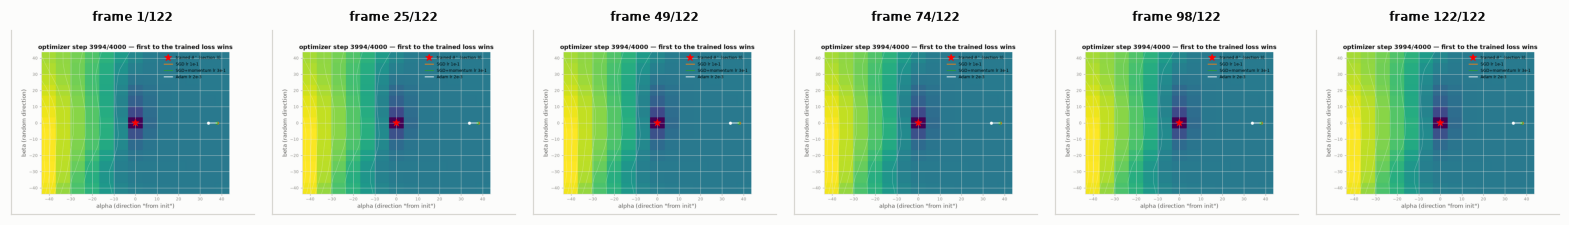

In [17]:
# ---- animation 3: the optimizer race on the infrasound landscape ----
fig, ax = plt.subplots(figsize=(6.6, 5))
from matplotlib.colors import LogNorm
im = ax.imshow(Z.T, origin='lower', extent=[float(alphas[0]), float(alphas[-1]),
                                           float(betas[0]), float(betas[-1])],
               cmap='viridis', aspect='auto', norm=LogNorm())
ax.contour(alphas, betas, Z.T, levels=10, colors='white', linewidths=0.5, alpha=0.6)
ax.plot(0, 0, 'r*', ms=15, label=r'trained $\theta^\star$ (section 3)')
trajs = {}
for (name, (path, _)), col in zip(runs.items(), ['C1', 'C2', 'w']):
    (ln,) = ax.plot([], [], color=col, lw=1.6, label=name)
    (pt,) = ax.plot([], [], 'o', color=col, ms=5)
    trajs[name] = (ln, pt)
ax.set_xlabel(r'alpha (direction "from init")'); ax.set_ylabel(r'beta (random direction)')
ax.legend(fontsize=8, loc='upper right'); title = ax.set_title('')

max_len = max(len(runs[n][1]) for n in runs)
stride = max(1, max_len // 120)                     # animate every stride-th stored step

def update(f):
    step = min(f * stride, max_len - 1)
    for name, (ln, pt) in trajs.items():
        path, _ = runs[name]
        k = min(step, len(path) - 1)
        ln.set_data(path[:k + 1, 0], path[:k + 1, 1])
        pt.set_data([path[k, 0]], [path[k, 1]])
    title.set_text(f'optimizer step {step + 1}/{max_len} — first to the trained loss wins')

show_anim(fig, update, frames=max_len // stride + 1, interval=90)

### 4.3 · Optional: overfitting under small data

A network with more parameters than data can memorize: the training/validation split is the
instrument that catches it. Below, the same model is trained on EIGHT atmospheres only —
watch the two curves separate. Remedies: more data (the PE solver is a free augmentation
engine) or less capacity.

8 training atmospheres: final TRAIN rel-L2 0.4760 vs VALIDATION 1.1247 (a gap of x2)


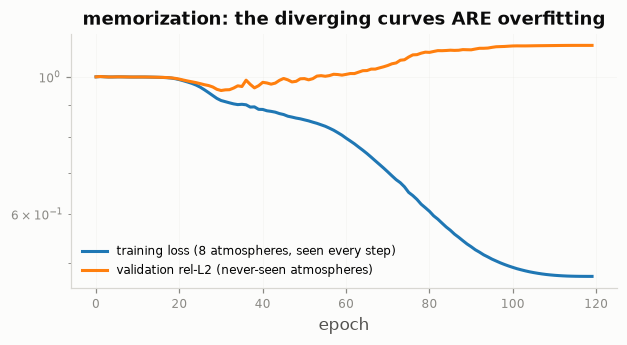

In [18]:
# ---- (c) overfitting: the same model trained on EIGHT atmospheres only ----
x8, y8 = Xtr[:8], Ytr[:8]
torch.manual_seed(0)
small = InfrasoundFFNO().to(DEVICE)
opt = torch.optim.AdamW(small.parameters(), lr=2e-3, weight_decay=1e-5)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=120)
loss_fn8 = get_loss('rel_l2')
tr_curve, va_curve = [], []
for ep in range(120):
    small.train()
    opt.zero_grad(set_to_none=True)
    loss = loss_fn8(small(x8), y8)            # the SAME 8 atmospheres at every step
    loss.backward(); opt.step(); sched.step()
    small.eval()
    with torch.no_grad():
        tr_curve.append(loss_fn8(small(x8), y8).item())
        va_curve.append(get_loss('rel_l2')(small(Xva), Yva).item())
print(f'8 training atmospheres: final TRAIN rel-L2 {tr_curve[-1]:.4f} vs VALIDATION '
      f'{va_curve[-1]:.4f} (a gap of x{va_curve[-1] / max(tr_curve[-1], 1e-9):.0f})')

fig, ax = plt.subplots(figsize=(6.4, 3))
ax.plot(tr_curve, label='training loss (8 atmospheres, seen every step)')
ax.plot(va_curve, label='validation rel-L2 (never-seen atmospheres)')
ax.set_yscale('log'); ax.set_xlabel('epoch'); ax.legend(fontsize=8); ax.grid(alpha=0.3)
ax.set_title('memorization: the diverging curves ARE overfitting')
plt.show()

## §5 · Evaluate on atmospheres the network never saw

test rel-L2 per atmosphere: mean 0.336 | worst 0.840


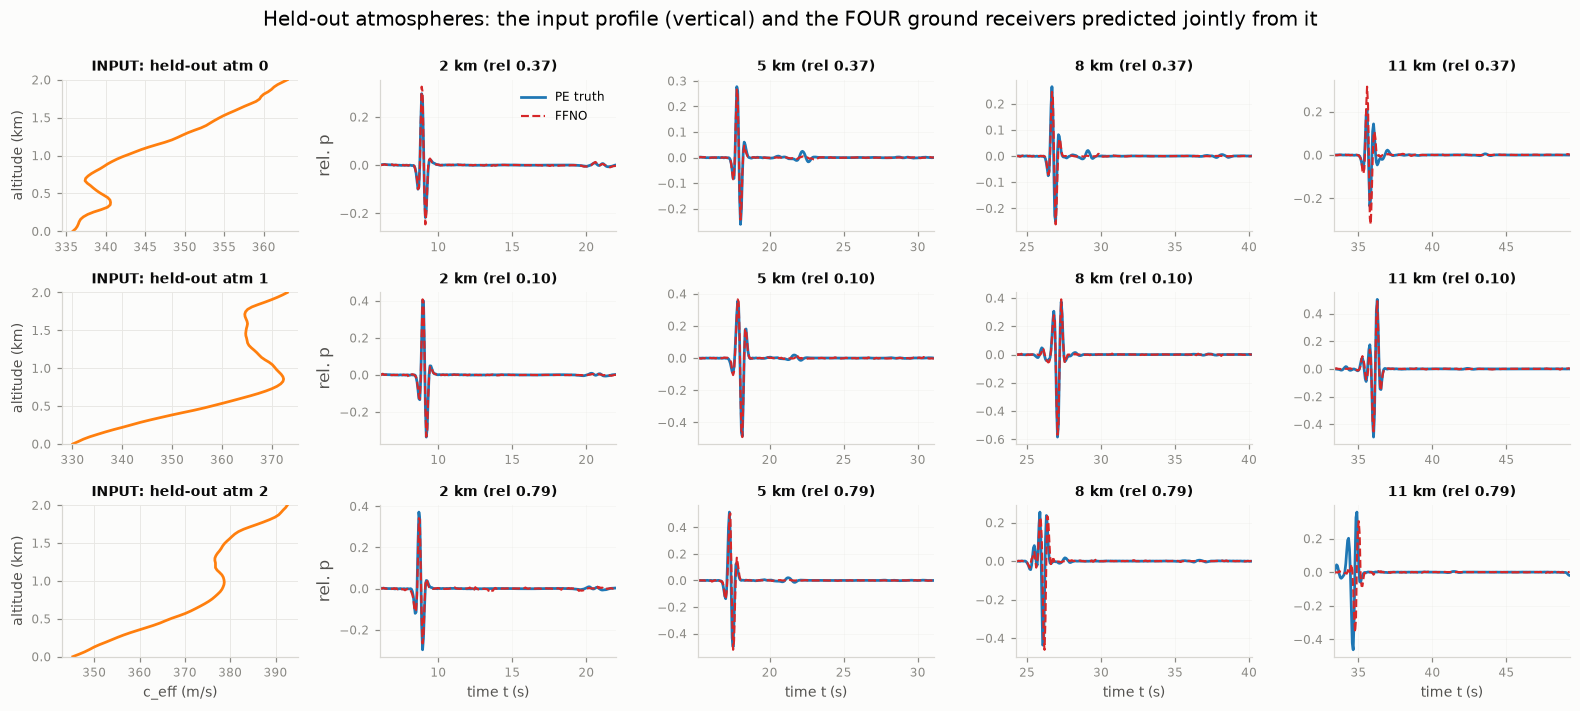

In [19]:
# ---- test atmospheres (H10): predicted vs PE truth, all four receivers ----
ffno.eval()
with torch.no_grad():
    pred_te = ffno(Xte).cpu().numpy() * float(p_sd)
truth_te = P[NTR + NVA:].numpy()
rel_te = (np.linalg.norm(pred_te - truth_te, axis=(1, 2))
          / np.linalg.norm(truth_te, axis=(1, 2)))
print(f'test rel-L2 per atmosphere: mean {rel_te.mean():.3f} | worst {rel_te.max():.3f}')

fig, ax = plt.subplots(3, 5, figsize=(14.5, 6.5))
for i in range(3):
    c_phys = Xte[i].cpu().numpy() * float(c_sd) + float(c_mu)
    ax[i, 0].plot(c_phys, z_km, color='C1', lw=1.8)
    ax[i, 0].set_ylim(0, 2); ax[i, 0].set_ylabel('altitude (km)', fontsize=9)
    if i == 2: ax[i, 0].set_xlabel('c_eff (m/s)', fontsize=9)
    ax[i, 0].set_title(f'INPUT: held-out atm {i}', fontsize=9)
    for j in range(4):
        t_j = tau_s + ranges_km[j] * 1000.0 / CFG.c_ref_mps      # absolute time per receiver
        ax[i, 1 + j].plot(t_j, truth_te[i, j], color='C0', lw=1.8, label='PE truth')
        ax[i, 1 + j].plot(t_j, pred_te[i, j], color='C3', ls='--', lw=1.4, label='FFNO')
        ax[i, 1 + j].set_xlim(float(t_j[0]), float(t_j[-1]))
        if i == 0 and j == 0: ax[i, 1 + j].legend(fontsize=8)
        if i == 2: ax[i, 1 + j].set_xlabel('time t (s)', fontsize=9)
        if j == 0: ax[i, 1 + j].set_ylabel('rel. p')
        ax[i, 1 + j].grid(alpha=0.3)
        ax[i, 1 + j].set_title(f'{int(ranges_km[j])} km (rel {rel_te[i]:.2f})', fontsize=9)
fig.suptitle('Held-out atmospheres: the input profile (vertical) and the FOUR ground '
             'receivers predicted jointly from it', y=0.99)
plt.tight_layout(); plt.show()

**Reading the figure.**

- **Learned**: travel times (phases), amplitude patterns, multi-path interference.
- **Bound by hypotheses**: everything is conditional on H1–H13. Change the source, the receiver
  geometry, or leave the synthetic ensemble (H10), and the operator must be retrained — what
  *transfers* is the method, not the weights.

## §6 · Takeaways — and using FFNOs on *your* problem

- **Operator thinking.** You never predicted "a number": input and output were *functions*
  (profile, waveforms), and resolution/grid details stayed out of the parameters (Lab 1, §5).
- **Factorization is a modeling act.** $C^2(m_x+m_y)$ instead of $C^2 m_x m_y$ parameters buys
  depth and speed at the price of separable filters (H13); depth and nonlinearities pay some of it
  back. State it as a hypothesis, test it against the full FNO on a small case.
- **Loss = experiment definition.** Relative vs absolute, weight decay, learning rate: §4 showed
  the geometry they create and why adaptive optimizers fit anisotropic operator landscapes.

**Checklist: Fourier operators on your application.**
1. Write $G^\dagger$ and the *generative* hypotheses of your data (our H1–H13): most
   failures are hypothesis violations, not architecture failures.
2. Choose grids so the informative band fits in few modes; check the spectra yourself (F2).
3. Encoder for the low-dimensional input, FFNO blocks on the output grid — this recipe
   (profile → field) reuses directly for tomography, source inversion, or surrogate solvers.
4. Train with AdamW + cosine; run the 3-minute landscape race (§4) before long trainings.
5. Evaluate on held-out *physical* cases (§5), per-channel and per-case, not only with a scalar.
6. If your geometry is irregular (sensor networks, meshes), go to **Lab 3**: graphs do not need
   a grid at all.

## Going further

**Factorized and Fourier neural operators**
- A. Tran, A. Mathews, L. Xie, C. S. Ong. *Factorized Fourier Neural Operators.* ICLR 2023.
  [arXiv:2111.13802](https://arxiv.org/abs/2111.13802)
- Z. Li et al. *Fourier Neural Operator for Parametric Partial Differential Equations.*
  ICLR 2021. [arXiv:2010.08895](https://arxiv.org/abs/2010.08895)
- N. Kovachki et al. *Neural Operator: Learning Maps Between Function Spaces with Applications
  to PDEs.* JMLR 24 (2023). [arXiv:2108.08481](https://arxiv.org/abs/2108.08481)

**Factorized FNOs for 3-D waves**
- F. Lehmann, F. Gatti, M. Bertin, D. Clouteau. *3D elastic wave propagation with a Factorized
  Fourier Neural Operator (F-FNO).* Computer Methods in Applied Mechanics and Engineering 420,
  116718 (2024). [doi:10.1016/j.cma.2023.116718](https://doi.org/10.1016/j.cma.2023.116718),
  [arXiv:2304.10242](https://arxiv.org/abs/2304.10242)
- F. Lehmann, F. Gatti, D. Clouteau. *Multiple-input Fourier Neural Operator (MIFNO) for
  source-dependent 3D elastodynamics.* Journal of Computational Physics 527, 113813 (2025).
  [doi:10.1016/j.jcp.2025.113813](https://doi.org/10.1016/j.jcp.2025.113813),
  [arXiv:2404.10115](https://arxiv.org/abs/2404.10115)
- F. Lehmann, F. Gatti, M. Bertin, D. Clouteau. *Synthetic ground motions in heterogeneous
  geologies from various sources: the HEMEW<sup>S</sup>-3D database.* Earth System Science Data 16,
  3949–3972 (2024). [doi:10.5194/essd-16-3949-2024](https://doi.org/10.5194/essd-16-3949-2024) — the
  open training database of the works above.

**Sound and infrasound propagation**
- M. D. Collins. *A split-step Padé solution for the parabolic equation method.* J. Acoust.
  Soc. Am. 93(4), 1736–1742 (1993). [doi:10.1121/1.406739](https://doi.org/10.1121/1.406739)
- O. A. Godin. *An effective quiescent medium for sound propagating through an inhomogeneous,
  moving fluid.* J. Acoust. Soc. Am. 112(4), 1269–1275 (2002) — when the effective sound speed
  is (and is not) enough. [doi:10.1121/1.1504853](https://doi.org/10.1121/1.1504853)
- D. P. Drob, J. M. Picone, M. Garcés. *Global morphology of infrasound propagation.* J. Geophys.
  Res. Atmos. 108(D21) (2003). [doi:10.1029/2002JD003307](https://doi.org/10.1029/2002JD003307)

**Next in this series:** Lab 3 replaces the Fourier grid by an irregular graph of seismic
stations; the Darcy-flow extension (`notebooks/extensions/scaleup_darcy_fno2d.ipynb`) trains a
2-D factorized FNO on a large database.

### Optional — save this interactive session measurement (Hedy only)
Identical to Lab 1: writes a JSON timing report on the cluster, a one-line summary elsewhere.

In [20]:
if HEDY_SESSION is not None:
    HEDY_SESSION.report()   # writes a JSON timing report on the Hedy cluster only
else:
    print('No Hedy session: nothing to report (laptop run).')

Interactive measurement saved: /home/projects/m26266/letma2026-ml-labs/notebooks/labs/reports/interactive/lab_ffno_infrasound_solution_25685_20261029T113352Z.json
Session elapsed (including user idle): 115.708 s
Peak kernel RSS: 1835.2 MiB
PyTorch CUDA peak allocated/reserved: 74.42 / 82.0 MiB
